# 02 — How sure are we, and which differences are real?

Two tools from statistics:

- **Confidence interval** — a mean from one snapshot is an estimate; the
  interval says how far off it could plausibly be.
- **Hypothesis test** — two groups always differ a little by chance; a test
  says whether the gap is bigger than chance would produce.

With ~10,000 listings almost any gap is "statistically significant", so each
comparison also reports the gap **in euros or percentage points** — the
number that matters.

Each test is tied to a question from notebook 01: is the 31-night band
really a separate market, and who would the licence phase-out reach?

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src import config as cfg
from src import cleaning

sns.set_theme(style="whitegrid", palette="colorblind")
rng = np.random.default_rng(cfg.SEED)
BANDS = ["tourist", "boundary", "seasonal"]
N_BOOT = 5000


def fmt_p(p):
    """p-values below float precision print as 0; say so instead."""
    return "< 1e-300" if p == 0 else f"{p:.2e}"

In [2]:
df = pd.read_csv(cfg.CLEAN_FILE)
df.groupby("stay_band")["price"].describe().loc[BANDS].round(1)

,count,mean,std,min,25%,50%,75%,max
stay_band,,,,,,,,
tourist,6399.0,268.0,145.7,16.0,181.0,245.0,324.0,1000.0
boundary,1902.0,98.9,76.5,13.0,46.0,82.5,130.0,894.0
seasonal,2138.0,88.5,70.3,15.0,53.0,72.0,101.8,979.0


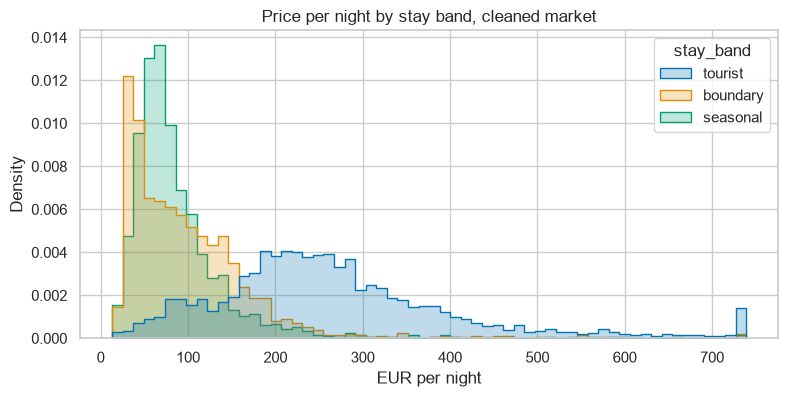

In [3]:
# One chart: price distribution per stay band (top 1% clipped so the axis is readable)
clip_at = df["price"].quantile(0.99)
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df.assign(price=df["price"].clip(upper=clip_at)),
             x="price", hue="stay_band", hue_order=BANDS,
             bins=60, element="step", stat="density", common_norm=False, ax=ax)
ax.set_xlabel("EUR per night")
ax.set_title("Price per night by stay band, cleaned market")
fig.savefig(cfg.FIGURES_DIR / "02_price_distribution.png", dpi=150, bbox_inches="tight")

Two shapes: tourist-band prices spread out to the right, while the boundary
and seasonal bands sit together at the low end. All three are right-skewed,
so the **median** is the honest "typical price"; the mean is for revenue math.

## Confidence interval for the mean price — two ways, per band

**Formula:** mean ± t · (std / √n).
**Bootstrap:** resample the data with replacement 5,000 times, take each
sample's mean, read the middle 95%. No formula, no assumptions — a good
cross-check.

In [4]:
def t_interval(values):
    """95% CI for the mean using the t formula."""
    se = values.std() / np.sqrt(len(values))
    return stats.t.interval(0.95, len(values) - 1, loc=values.mean(), scale=se)


def bootstrap_interval(values, statistic=np.mean):
    """95% CI for any statistic by resampling with replacement."""
    arr = values.to_numpy()
    boots = [statistic(rng.choice(arr, size=len(arr), replace=True)) for _ in range(N_BOOT)]
    return np.percentile(boots, [2.5, 97.5])


rows = []
for band in BANDS:
    price = df.loc[df["stay_band"] == band, "price"]
    lo_f, hi_f = t_interval(price)
    lo_b, hi_b = bootstrap_interval(price)
    rows.append({"band": band, "n": len(price), "mean": price.mean(),
                 "formula_low": lo_f, "formula_high": hi_f,
                 "boot_low": lo_b, "boot_high": hi_b})
pd.DataFrame(rows).set_index("band").round(1)

,n,mean,formula_low,formula_high,boot_low,boot_high
band,,,,,,
tourist,6399,268.0,264.4,271.5,264.5,271.6
boundary,1902,98.9,95.5,102.4,95.5,102.5
seasonal,2138,88.5,85.6,91.5,85.6,91.7


The formula and the bootstrap agree closely in every band. The intervals
for the boundary and seasonal bands are a few euros wide and sit far below
the tourist band's.

## Test 1 — Do entire homes cost more than private rooms? (sanity check)

Tourist band only, so the stay rules are the same for both groups.

- **H0:** the mean price is the same for both
- **Test:** two-sample t-test (Welch's version — does not assume the two
  groups have equal spread), alpha = 0.05

In [5]:
tourist = df[df["stay_band"] == "tourist"]
entire = tourist.loc[tourist["room_type"] == "Entire home/apt", "price"]
private = tourist.loc[tourist["room_type"] == "Private room", "price"]

t_stat, p_value = stats.ttest_ind(entire, private, equal_var=False)

print(f"entire homes  : n={len(entire):,}, mean={entire.mean():.0f} EUR")
print(f"private rooms : n={len(private):,}, mean={private.mean():.0f} EUR")
print(f"difference    : {entire.mean() - private.mean():.0f} EUR per night")
print(f"p-value       : {fmt_p(p_value)}")

entire homes  : n=4,918, mean=298 EUR
private rooms : n=1,311, mean=168 EUR
difference    : 131 EUR per night
p-value       : 2.29e-205


As expected: a large gap and a tiny p-value. If the method missed *this*,
something would be wrong.

## Test 2 — Is the 31-night band priced like tourist or seasonal stays?

Notebook 01 showed the boundary band (exactly 31 nights) almost never holds
an HUT licence. If it is really part of the seasonal market, its prices
should be close to the seasonal band's and far from the tourist band's.

Two comparisons, each with a Welch t-test on the means and — because prices
are skewed — a **bootstrap CI for the difference in medians**.

In [6]:
def median_gap_interval(a, b):
    """95% bootstrap CI for median(a) - median(b)."""
    a_arr, b_arr = a.to_numpy(), b.to_numpy()
    gaps = [np.median(rng.choice(a_arr, len(a_arr))) - np.median(rng.choice(b_arr, len(b_arr)))
            for _ in range(N_BOOT)]
    return np.percentile(gaps, [2.5, 97.5])


price_of = {band: df.loc[df["stay_band"] == band, "price"] for band in BANDS}

for other in ["tourist", "seasonal"]:
    a, b = price_of["boundary"], price_of[other]
    _, p_value = stats.ttest_ind(a, b, equal_var=False)
    lo, hi = median_gap_interval(a, b)
    print(f"boundary vs {other}:")
    print(f"   mean gap   : {a.mean() - b.mean():+.0f} EUR  (p = {fmt_p(p_value)})")
    print(f"   median gap : {a.median() - b.median():+.1f} EUR, 95% CI [{lo:+.1f}, {hi:+.1f}]")

boundary vs tourist:
   mean gap   : -169 EUR  (p = < 1e-300)
   median gap : -162.5 EUR, 95% CI [-167.0, -157.0]


boundary vs seasonal:
   mean gap   : +10 EUR  (p = 7.85e-06)
   median gap : +10.5 EUR, 95% CI [+6.0, +14.0]


Both gaps are statistically "real" — with thousands of listings, even a
few euros clear the bar. The **size** is the point: the boundary band sits
about ten euros above seasonal prices and over 150 euros below tourist
prices. On price, as on licences, 31-night listings sit with the seasonal
market.

**What this cannot show:** whether these listings are *let* for a month.
A 31-night minimum is an asking term; the file does not record actual stays.

## Test 3 — HUT licence share: tourist band vs boundary band

A licence is yes/no per listing, so this compares two **rates**. The right
tool is a **two-proportion z-test**, not a t-test.

Licence tests use every listing with a known minimum stay (not only priced
ones): listings without a price still carry a licence declaration.

In [7]:
raw = cleaning.add_columns(cleaning.load_listings().dropna(subset=["minimum_nights"]))


def two_proportion_z(yes_a, n_a, yes_b, n_b):
    """z statistic and two-sided p-value for p_a - p_b."""
    p_pool = (yes_a + yes_b) / (n_a + n_b)
    se = np.sqrt(p_pool * (1 - p_pool) * (1 / n_a + 1 / n_b))
    z = (yes_a / n_a - yes_b / n_b) / se
    return z, 2 * (1 - stats.norm.cdf(abs(z)))


tourist_raw = raw[raw["stay_band"] == "tourist"]
boundary_raw = raw[raw["stay_band"] == "boundary"]

z, p_value = two_proportion_z(tourist_raw["has_hut"].sum(), len(tourist_raw),
                              boundary_raw["has_hut"].sum(), len(boundary_raw))
print(f"tourist band : {tourist_raw['has_hut'].mean():.1%} of {len(tourist_raw):,} show an HUT licence")
print(f"boundary band: {boundary_raw['has_hut'].mean():.1%} of {len(boundary_raw):,}")
print(f"difference   : {(tourist_raw['has_hut'].mean() - boundary_raw['has_hut'].mean()) * 100:.1f} "
      f"percentage points, z = {z:.1f}, p = {fmt_p(p_value)}")

tourist band : 67.9% of 7,927 show an HUT licence
boundary band: 0.8% of 2,504
difference   : 67.1 percentage points, z = 58.6, p = < 1e-300


A near-total split at exactly the legal line. A missing HUT number is not
proof of anything illegal — a seasonal let does not need one.

## Test 4 — Do the national declarations depend on the stay band?

The national code says *tourist* (`TU`) or *non-tourist* (`NT`). If hosts'
declarations matched nothing, the TU/NT split would look the same in every
stay band. A **chi-square test of independence** checks that on the
band × declaration table (listings with a readable NRUA code only).

In [8]:
coded = raw[raw["national_licence"].isin(["nrua_tourist", "nrua_seasonal"])]
table = pd.crosstab(coded["stay_band"], coded["national_licence"]).loc[BANDS]
chi2, p_value, dof, expected = stats.chi2_contingency(table)

# Cramér's V: effect size for a contingency table (0 = no link, 1 = perfect)
cramers_v = np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))

print(table.to_string())
print()
print(f"chi2 = {chi2:,.0f}, dof = {dof}, p = {fmt_p(p_value)}, Cramér's V = {cramers_v:.2f}")

national_licence  nrua_seasonal  nrua_tourist
stay_band                                    
tourist                     117          4475
boundary                   1074            28
seasonal                   1480            19

chi2 = 6,507, dof = 2, p = < 1e-300, Cramér's V = 0.95


The p-value says the link is not chance; **Cramér's V** says how strong it
is, on a 0–1 scale. A value near 1 means a host's declared use almost
perfectly predicts which side of the 31-night line the listing sits on —
declarations and asking terms are consistent.

**What this cannot show:** whether the declarations are *true*. Consistency
between two things a host writes is not an inspection.

## Test 5 — Who would the licence phase-out reach?

Within the tourist band, compare the share of listings run by hosts with 5+
listings: those **with** an HUT licence vs those **without** one.

In [9]:
with_hut = tourist_raw[tourist_raw["has_hut"]]
without_hut = tourist_raw[~tourist_raw["has_hut"]]

z, p_value = two_proportion_z(with_hut["is_professional"].sum(), len(with_hut),
                              without_hut["is_professional"].sum(), len(without_hut))
print(f"with HUT   : {with_hut['is_professional'].mean():.1%} of {len(with_hut):,} run by 5+ hosts")
print(f"without HUT: {without_hut['is_professional'].mean():.1%} of {len(without_hut):,}")
print(f"difference : {(with_hut['is_professional'].mean() - without_hut['is_professional'].mean()) * 100:+.1f} "
      f"percentage points, z = {z:.1f}, p = {fmt_p(p_value)}")

with HUT   : 65.7% of 5,383 run by 5+ hosts
without HUT: 43.9% of 2,544
difference : +21.7 percentage points, z = 18.3, p = < 1e-300


This describes who holds the listings the phase-out targets — not whether
the phase-out is a good idea. The data shows *who* is affected; judging the
trade-off (housing supply vs tourism income and jobs) needs evidence this
file does not contain.

## What I found

1. **Typical prices, with uncertainty.** Median per night: tourist €245,
   boundary €82.5, seasonal €72. 95% CIs for the mean are narrow
   (tourist [264, 272], boundary [96, 102], seasonal [86, 92]) and the
   formula and bootstrap agree.
2. **Entire homes cost more** — €131 more per night than private rooms in
   the tourist band (p < 1e-200). A sanity check, not a finding.
3. **The 31-night band is priced like seasonal lets.** Its median is
   €162.5 below the tourist band (95% CI [−167, −157]) and only €10.5
   above the seasonal band (95% CI [+6, +14]).
4. **Licences split at the legal line.** 67.9% of tourist-band listings
   show an HUT licence vs 0.8% of 31-night listings (67 points, z = 58.6).
5. **Declarations are consistent with asking terms.** Among listings with
   an NRUA code, declared use (TU/NT) and stay band are almost perfectly
   linked (Cramér's V = 0.95). Consistent is not the same as verified.
6. **The phase-out reaches professional hosts most.** 65.7% of HUT
   listings belong to hosts with 5+ listings vs 43.9% of tourist-band
   listings without an HUT (+21.7 points, z = 18.3).


**Next:** `03_price_regression.ipynb` — what drives the price once room
type, location and stay band are held fixed?